In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("../data/train.csv")

train.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_14864\455601417.py:6: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("../data/train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
train.shape

(1017209, 9)

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [7]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [8]:
train.duplicated().sum()

np.int64(0)

In [9]:
train["Date"] = pd.to_datetime(train["Date"])

In [10]:
print(train["Date"].min())
print(train["Date"].max())

2013-01-01 00:00:00
2015-07-31 00:00:00


In [11]:
train["Sales"].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

In [12]:
print((train["Sales"] == 0).sum())
print((train["Open"] == 0).sum())

172871
172817


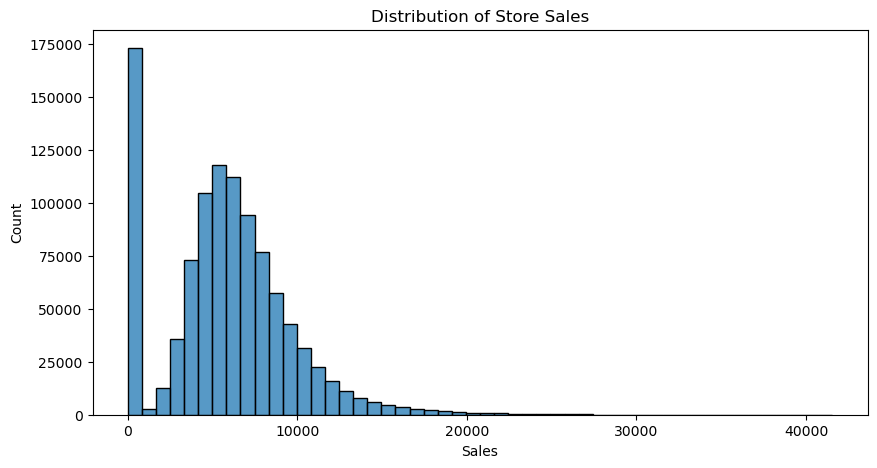

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(data=train, x="Sales", bins=50)
plt.title("Distribution of Store Sales")
plt.show()

In [14]:
sales_by_day = train.groupby("DayOfWeek")["Sales"].mean()
print(sales_by_day)

DayOfWeek
1    7809.044510
2    7005.244467
3    6555.884138
4    6247.575913
5    6723.274305
6    5847.562599
7     204.183189
Name: Sales, dtype: float64


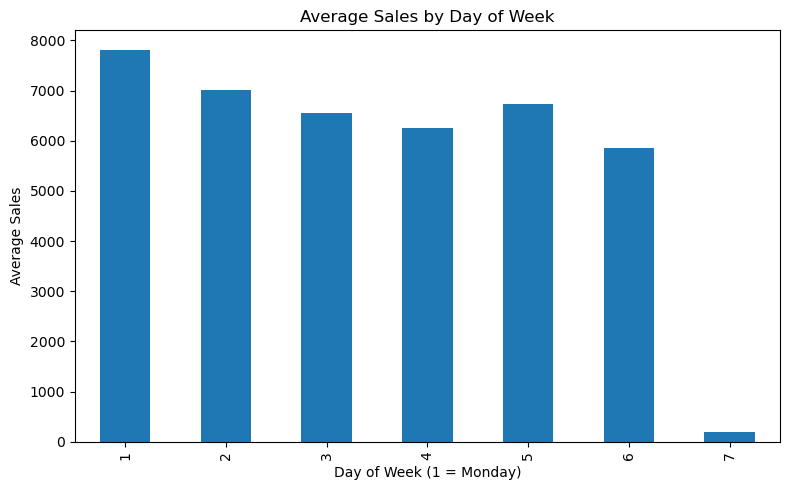

In [15]:
sales_by_day.plot(kind="bar", figsize=(8, 5))
plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week (1 = Monday)")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

In [17]:
print(train.groupby("Promo")["Sales"].mean())

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


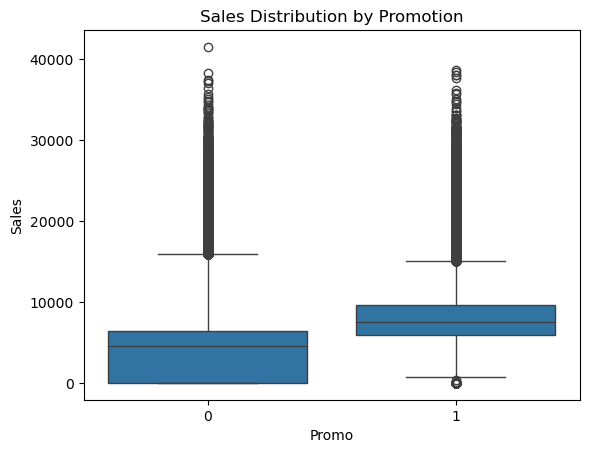

In [18]:
sns.boxplot(data=train, x="Promo", y="Sales")
plt.title("Sales Distribution by Promotion")
plt.show()

In [19]:
daily_sales = (
    train.groupby("Date", as_index=False)["Sales"]
    .sum()
)

daily_sales.head()

,Date,Sales
0,2013-01-01,97235
1,2013-01-02,6949829
2,2013-01-03,6347820
3,2013-01-04,6638954
4,2013-01-05,5951593


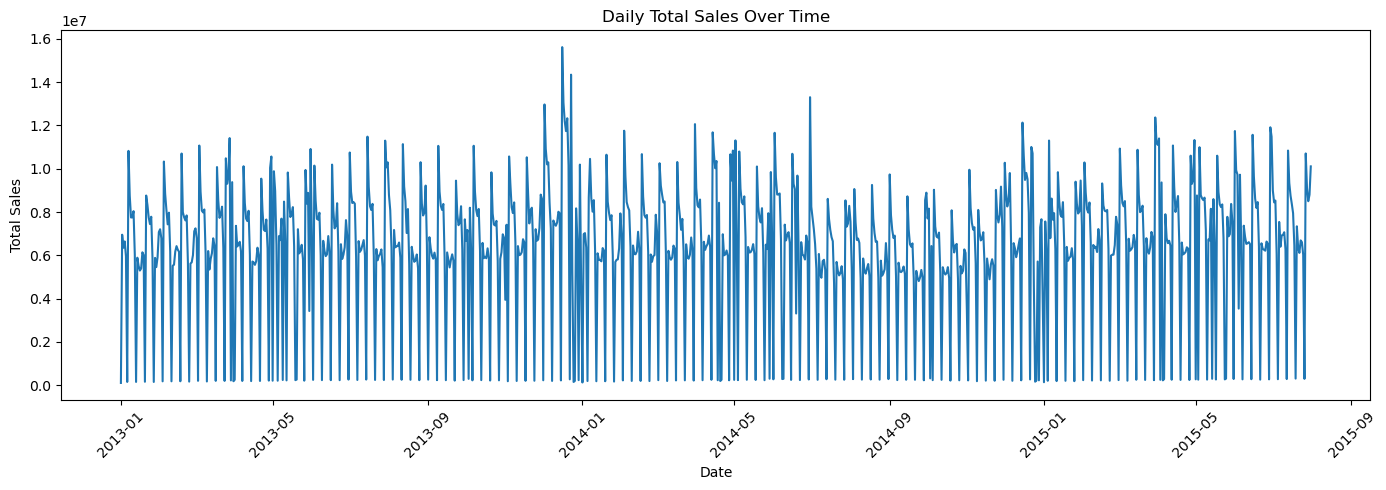

In [20]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"]
)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
store = pd.read_csv("../data/store.csv")
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [22]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [23]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [24]:
print(store["StoreType"].value_counts())

StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64


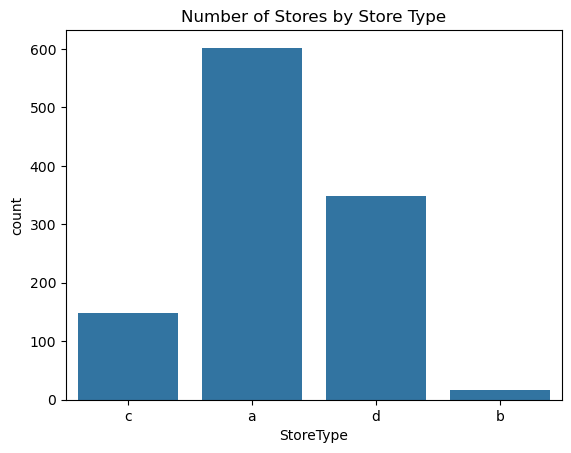

In [25]:
sns.countplot(data=store, x="StoreType")
plt.title("Number of Stores by Store Type")
plt.show()

In [26]:
df = train.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [27]:
print("Before merge:", train.shape)
print("After merge:", df.shape)

Before merge: (1017209, 9)
After merge: (1017209, 18)


In [28]:
store_type_sales = df.groupby("StoreType")["Sales"].mean()
print(store_type_sales)

StoreType
a     5738.179710
b    10058.837334
c     5723.629246
d     5641.819243
Name: Sales, dtype: float64


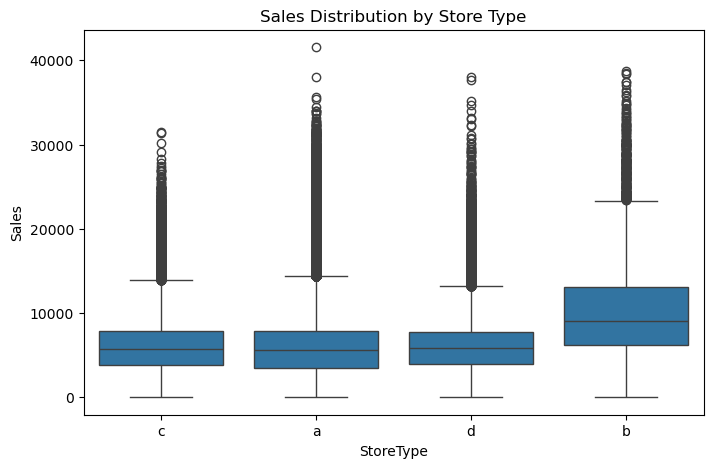

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="StoreType",
    y="Sales"
)

plt.title("Sales Distribution by Store Type")
plt.show()

In [30]:
df["CompetitionDistance"].describe()

count    1.014567e+06
mean     5.430086e+03
std      7.715324e+03
min      2.000000e+01
25%      7.100000e+02
50%      2.330000e+03
75%      6.890000e+03
max      7.586000e+04
Name: CompetitionDistance, dtype: float64

In [31]:
df.isnull().sum().sort_values(ascending=False)

PromoInterval                508031
Promo2SinceYear              508031
Promo2SinceWeek              508031
CompetitionOpenSinceYear     323348
CompetitionOpenSinceMonth    323348
CompetitionDistance            2642
DayOfWeek                         0
Promo2                            0
Assortment                        0
Store                             0
SchoolHoliday                     0
StateHoliday                      0
Promo                             0
Open                              0
Customers                         0
Sales                             0
Date                              0
StoreType                         0
dtype: int64

In [32]:
print(df["CompetitionDistance"].isnull().sum())
print(df["CompetitionDistance"].describe())

2642
count    1.014567e+06
mean     5.430086e+03
std      7.715324e+03
min      2.000000e+01
25%      7.100000e+02
50%      2.330000e+03
75%      6.890000e+03
max      7.586000e+04
Name: CompetitionDistance, dtype: float64


In [33]:
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(
    df["CompetitionDistance"].median()
)

In [34]:
df["CompetitionOpenSinceMonth"] = df["CompetitionOpenSinceMonth"].fillna(0)
df["CompetitionOpenSinceYear"] = df["CompetitionOpenSinceYear"].fillna(0)

In [35]:
df["Promo2SinceWeek"] = df["Promo2SinceWeek"].fillna(0)
df["Promo2SinceYear"] = df["Promo2SinceYear"].fillna(0)
df["PromoInterval"] = df["PromoInterval"].fillna("None")

In [36]:
df["Year"] = df["Date"].dt.year

In [37]:
df["Month"] = df["Date"].dt.month

In [38]:
df["Day"] = df["Date"].dt.day

In [39]:
df["DayOfWeek"] = df["Date"].dt.dayofweek

In [40]:
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

In [41]:
df[[
    "Date","Store","Sales",
    "Year","Month",
    "Day","DayOfWeek","IsWeekend"
]].head(10)

,Date,Store,Sales,Year,Month,Day,DayOfWeek,IsWeekend
0,2015-07-31,1,5263,2015,7,31,4,0
1,2015-07-31,2,6064,2015,7,31,4,0
2,2015-07-31,3,8314,2015,7,31,4,0
3,2015-07-31,4,13995,2015,7,31,4,0
4,2015-07-31,5,4822,2015,7,31,4,0
5,2015-07-31,6,5651,2015,7,31,4,0
6,2015-07-31,7,15344,2015,7,31,4,0
7,2015-07-31,8,8492,2015,7,31,4,0
8,2015-07-31,9,8565,2015,7,31,4,0
9,2015-07-31,10,7185,2015,7,31,4,0


In [42]:
print("Minimum date:", df["Date"].min())
print("Maximum date:", df["Date"].max())

Minimum date: 2013-01-01 00:00:00
Maximum date: 2015-07-31 00:00:00


In [43]:
cutoff_date = df["Date"].max() - pd.Timedelta(days=42)

print("Cutoff date:", cutoff_date)

Cutoff date: 2015-06-19 00:00:00


In [44]:
train_data = df[df["Date"] < cutoff_date].copy()

In [45]:
valid_data = df[df["Date"] >= cutoff_date].copy()

In [46]:
print("Training data:", train_data.shape)
print("Validation data:", valid_data.shape)

Training data: (969264, 22)
Validation data: (47945, 22)


In [47]:
print("Training dates:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nValidation dates:")
print(valid_data["Date"].min(), "to", valid_data["Date"].max())

Training dates:
2013-01-01 00:00:00 to 2015-06-18 00:00:00

Validation dates:
2015-06-19 00:00:00 to 2015-07-31 00:00:00


In [48]:
features = [
    "Store",
    "DayOfWeek",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "StoreType",
    "Assortment",
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2",
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "Year","Month", "Day",
    "IsWeekend"
]

In [49]:
X_train = train_data[features]
y_train = train_data["Sales"]

X_valid = valid_data[features]
y_valid = valid_data["Sales"]

In [50]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (969264, 17)
y_train: (969264,)
X_valid: (47945, 17)
y_valid: (47945,)


In [51]:
print(X_train.dtypes)

Store                          int64
DayOfWeek                      int32
Promo                          int64
StateHoliday                  object
SchoolHoliday                  int64
StoreType                     object
Assortment                    object
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
Year                           int32
Month                          int32
Day                            int32
IsWeekend                      int64
dtype: object


In [52]:
categorical_features = [
    "StateHoliday",
    "StoreType",
    "Assortment"
]

print(X_train[categorical_features].head())

      StateHoliday StoreType Assortment
47945            0         c          a
47946            0         a          a
47947            0         a          a
47948            0         c          c
47949            0         a          a


In [53]:
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_valid_encoded = pd.get_dummies(
    X_valid,
    columns=categorical_features,
    dtype=int
)

In [54]:
X_train_encoded, X_valid_encoded = X_train_encoded.align(
    X_valid_encoded,
    join="left",
    axis=1,
    fill_value=0
)

In [55]:
print("Training shape:", X_train_encoded.shape)
print("Validation shape:", X_valid_encoded.shape)

X_train_encoded.head()

Training shape: (969264, 26)
Validation shape: (47945, 26)


,Store,DayOfWeek,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,...,StateHoliday_a,StateHoliday_b,StateHoliday_c,StoreType_a,StoreType_b,StoreType_c,StoreType_d,Assortment_a,Assortment_b,Assortment_c
47945,1,3,1,0,1270.0,9.0,2008.0,0,0.0,0.0,...,0,0,0,0,0,1,0,1,0,0
47946,2,3,1,0,570.0,11.0,2007.0,1,13.0,2010.0,...,0,0,0,1,0,0,0,1,0,0
47947,3,3,1,0,14130.0,12.0,2006.0,1,14.0,2011.0,...,0,0,0,1,0,0,0,1,0,0
47948,4,3,1,0,620.0,9.0,2009.0,0,0.0,0.0,...,0,0,0,0,0,1,0,0,0,1
47949,5,3,1,0,29910.0,4.0,2015.0,0,0.0,0.0,...,0,0,0,1,0,0,0,1,0,0


In [56]:
baseline_prediction = y_train.mean()

print("Baseline prediction:", baseline_prediction)

Baseline prediction: 5760.668788895492


In [57]:
baseline_pred = np.full(
    len(y_valid),
    baseline_prediction
)

print(baseline_pred[:10])

[5760.6687889 5760.6687889 5760.6687889 5760.6687889 5760.6687889
 5760.6687889 5760.6687889 5760.6687889 5760.6687889 5760.6687889]


In [58]:
from sklearn.metrics import mean_squared_error

baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, baseline_pred)
)

print("Baseline RMSE:", baseline_rmse)

Baseline RMSE: 3721.4312815186645


In [59]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [60]:
rf_pred = rf_model.predict(X_valid_encoded)

print(rf_pred[:10])

[ 7200.66124193  6957.82038485  8879.37502689 11186.76628436
  6401.2663041   7195.25559906 11290.7613683   8027.79299331
  9180.90144261  7483.48793772]


In [61]:
rf_rmse = np.sqrt(
    mean_squared_error(y_valid, rf_pred)
)

print("Baseline RMSE:", baseline_rmse)
print("Random Forest RMSE:", rf_rmse)

Baseline RMSE: 3721.4312815186645
Random Forest RMSE: 1356.2143093052891


In [62]:
from sklearn.metrics import mean_absolute_error

rf_mae = mean_absolute_error(y_valid, rf_pred)

print("Random Forest MAE:", rf_mae)

Random Forest MAE: 859.4024350945937


In [63]:
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))

print("Random Forest RMSE:", rf_rmse)

Random Forest RMSE: 1356.2143093052891


In [64]:
from sklearn.metrics import r2_score

rf_r2 = r2_score(y_valid, rf_pred)

print("Random Forest R²:", rf_r2)

Random Forest R²: 0.8664375158497475


In [65]:
print("===== MODEL PERFORMANCE =====")
print("Baseline RMSE:", baseline_rmse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest MAE:", rf_mae)
print("Random Forest R²:", rf_r2)

===== MODEL PERFORMANCE =====
Baseline RMSE: 3721.4312815186645
Random Forest RMSE: 1356.2143093052891
Random Forest MAE: 859.4024350945937
Random Forest R²: 0.8664375158497475


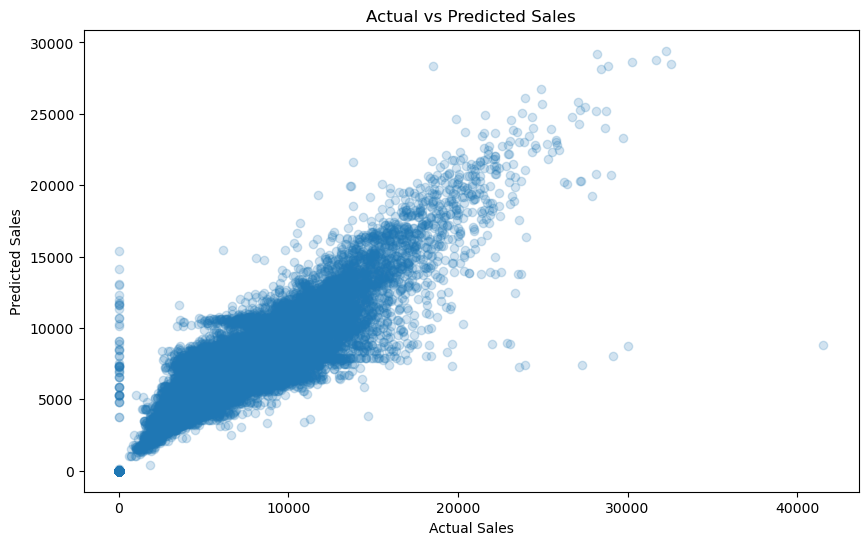

In [66]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_valid,
    rf_pred,
    alpha=0.2
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

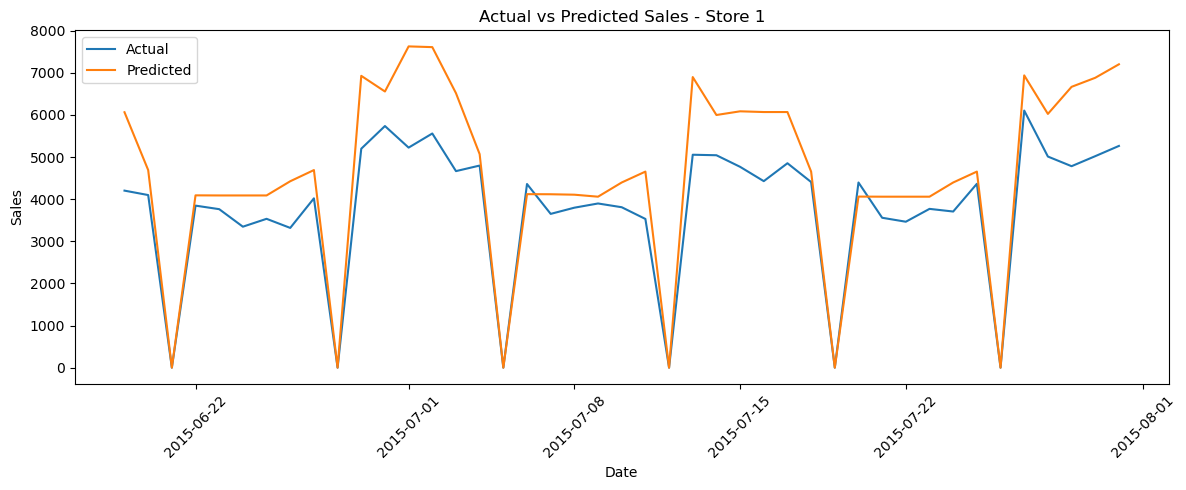

In [67]:
store_id = 1

store_valid = valid_data[valid_data["Store"] == store_id].copy()

store_predictions = rf_model.predict(
    X_valid_encoded.loc[store_valid.index]
)

plt.figure(figsize=(12, 5))

plt.plot(
    store_valid["Date"],
    store_valid["Sales"],
    label="Actual"
)

plt.plot(
    store_valid["Date"],
    store_predictions,
    label="Predicted"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title(f"Actual vs Predicted Sales - Store {store_id}")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [68]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_encoded.columns
).sort_values(ascending=False)

print(feature_importance.head(15))

DayOfWeek                    0.419332
CompetitionDistance          0.097401
Promo                        0.086641
Store                        0.075607
StateHoliday_a               0.063637
CompetitionOpenSinceYear     0.037139
StoreType_b                  0.036669
CompetitionOpenSinceMonth    0.029835
Promo2SinceYear              0.023547
StateHoliday_b               0.023263
Month                        0.019387
Day                          0.018326
Promo2SinceWeek              0.017129
StateHoliday_c               0.010279
Assortment_a                 0.009616
dtype: float64


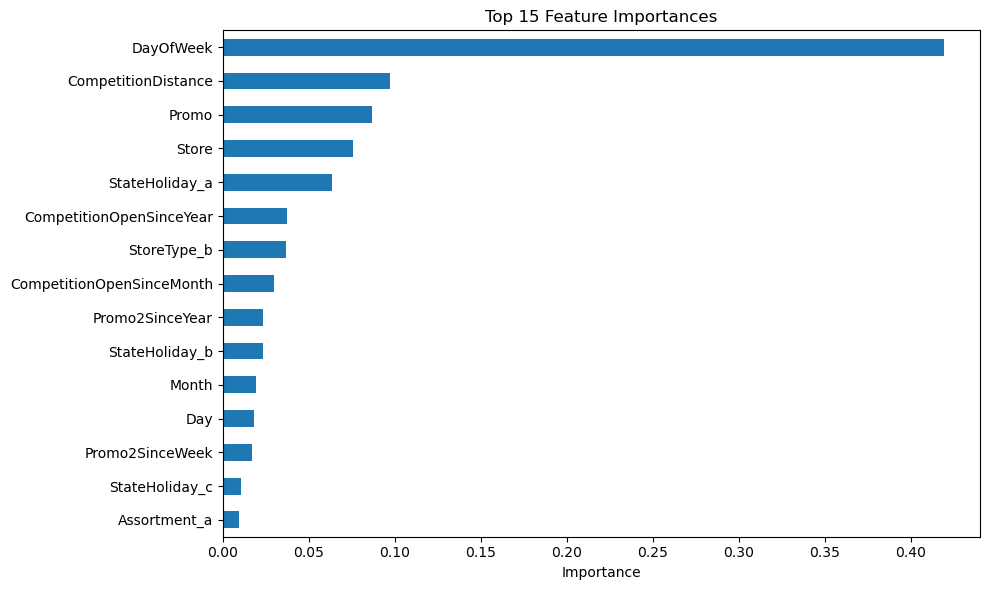

In [69]:
plt.figure(figsize=(10, 6))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [70]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

gb_model.fit(X_train_encoded, y_train)

,loss,'squared_error'
,quantile,None
,learning_rate,0.1
,max_iter,200
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'


In [71]:
gb_pred = gb_model.predict(X_valid_encoded)

gb_rmse = np.sqrt(
    mean_squared_error(y_valid, gb_pred)
)

gb_mae = mean_absolute_error(
    y_valid,
    gb_pred
)

gb_r2 = r2_score(
    y_valid,
    gb_pred
)

print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting R²:", gb_r2)

Gradient Boosting RMSE: 1456.9802263000665
Gradient Boosting MAE: 1033.4595277839778
Gradient Boosting R²: 0.8458529709343897


In [72]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Gradient Boosting"
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse,
        gb_rmse
    ],
    "MAE": [
        mean_absolute_error(y_valid, baseline_pred),
        rf_mae,
        gb_mae
    ],
    "R2": [
        r2_score(y_valid, baseline_pred),
        rf_r2,
        gb_r2
    ]
})

results

,Model,RMSE,MAE,R2
0,Baseline,3721.431282,2746.098764,-0.005652
1,Random Forest,1356.214309,859.402435,0.866438
2,Gradient Boosting,1456.980226,1033.459528,0.845853


In [76]:
df["Quarter"] = df["Date"].dt.quarter
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)
df["IsMonthStart"] = df["Date"].dt.is_month_start.astype(int)
df["IsMonthEnd"] = df["Date"].dt.is_month_end.astype(int)

In [80]:
features = [
    "Store",
    "DayOfWeek",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "StoreType",
    "Assortment",
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2",
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "Year",
    "Month",
    "Day",
    "IsWeekend",
    "Quarter",
    "WeekOfYear",
    "IsMonthStart",
    "IsMonthEnd"
]

In [81]:
train_data = df[df["Date"] < cutoff_date].copy()
valid_data = df[df["Date"] >= cutoff_date].copy()

In [82]:
X_train = train_data[features]
y_train = train_data["Sales"]

X_valid = valid_data[features]
y_valid = valid_data["Sales"]

categorical_features = [
    "StateHoliday",
    "StoreType",
    "Assortment"
]

In [83]:
print(X_train.columns.tolist())

['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Year', 'Month', 'Day', 'IsWeekend', 'Quarter', 'WeekOfYear', 'IsMonthStart', 'IsMonthEnd']


In [84]:
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_valid_encoded = pd.get_dummies(
    X_valid,
    columns=categorical_features,
    dtype=int
)

X_train_encoded, X_valid_encoded = X_train_encoded.align(
    X_valid_encoded,
    join="left",
    axis=1,
    fill_value=0
)

In [87]:
final_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    X_train_encoded,
    y_train
)

,n_estimators,150
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [88]:
final_pred = final_model.predict(X_valid_encoded)

final_rmse = np.sqrt(
    mean_squared_error(y_valid, final_pred)
)

final_mae = mean_absolute_error(
    y_valid,
    final_pred
)

final_r2 = r2_score(
    y_valid,
    final_pred
)

print("Final RMSE:", final_rmse)
print("Final MAE:", final_mae)
print("Final R²:", final_r2)

Final RMSE: 1328.8180582632624
Final MAE: 844.7046223723819
Final R²: 0.8717790807073843


In [89]:
final_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Final Random Forest"
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse,
        final_rmse
    ],
    "MAE": [
        mean_absolute_error(y_valid, baseline_pred),
        rf_mae,
        final_mae
    ],
    "R2": [
        r2_score(y_valid, baseline_pred),
        rf_r2,
        final_r2
    ]
})

final_results

,Model,RMSE,MAE,R2
0,Baseline,3721.431282,2746.098764,-0.005652
1,Random Forest,1356.214309,859.402435,0.866438
2,Final Random Forest,1328.818058,844.704622,0.871779


In [90]:
test = pd.read_csv("../data/test.csv")

test["Date"] = pd.to_datetime(test["Date"])

test = test.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

In [91]:
test["Year"] = test["Date"].dt.year
test["Month"] = test["Date"].dt.month
test["Day"] = test["Date"].dt.day
test["DayOfWeek"] = test["Date"].dt.dayofweek

test["IsWeekend"] = (
    test["DayOfWeek"] >= 5
).astype(int)

test["Quarter"] = test["Date"].dt.quarter
test["WeekOfYear"] = test["Date"].dt.isocalendar().week.astype(int)

test["IsMonthStart"] = (
    test["Date"].dt.is_month_start
).astype(int)

test["IsMonthEnd"] = (
    test["Date"].dt.is_month_end
).astype(int)

test["CompetitionDistance"] = test[
    "CompetitionDistance"
].fillna(
    df["CompetitionDistance"].median()
)

test["CompetitionOpenSinceMonth"] = test[
    "CompetitionOpenSinceMonth"
].fillna(0)

test["CompetitionOpenSinceYear"] = test[
    "CompetitionOpenSinceYear"
].fillna(0)

test["Promo2SinceWeek"] = test[
    "Promo2SinceWeek"
].fillna(0)

test["Promo2SinceYear"] = test[
    "Promo2SinceYear"
].fillna(0)

test["PromoInterval"] = test[
    "PromoInterval"
].fillna("None")

In [92]:
X_test = test[features]

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_features,
    dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print(X_test_encoded.shape)

(41088, 30)


In [93]:
X_full = df[features]
y_full = df["Sales"]

In [94]:
X_full_encoded = pd.get_dummies(
    X_full,
    columns=categorical_features,
    dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_full_encoded.columns,
    fill_value=0
)

In [95]:
production_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

production_model.fit(
    X_full_encoded,
    y_full
)

,n_estimators,150
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [96]:
test_predictions = production_model.predict(
    X_test_encoded
)

print(test_predictions[:10])

[5839.4806463  7718.61330306 7869.64583684 6918.61511501 7702.4643884
 6257.6526154  8110.26706657 8023.7880703  5968.72994033 5986.63453296]


In [97]:
test_predictions[test["Open"] == 0] = 0 

In [98]:
predictions = pd.DataFrame({
    "Id": test["Id"],
    "Sales": test_predictions
})

predictions.head()

,Id,Sales
0,1,5839.480646
1,2,7718.613303
2,3,7869.645837
3,4,6918.615115
4,5,7702.464388


In [99]:
predictions.to_csv(
    "../data/predictions.csv",
    index=False
)

In [100]:
predictions.shape

(41088, 2)

In [101]:
predictions.head()

,Id,Sales
0,1,5839.480646
1,2,7718.613303
2,3,7869.645837
3,4,6918.615115
4,5,7702.464388
